In [12]:
import polars as pl
# import simplstyles
from cmcrameri import cm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from archetypes_re2020.archetypes.buildings_based_archetypes_db import load_parquet_data, INPUT_PATH
from archetypes_re2020.data.source import INPUT_PATHS

from archetypes_re2020.data.remove_extreme_outliers import outliers

df_buildings = pl.read_csv(
    source=INPUT_PATHS["BUILDINGS"], ignore_errors=True
    )

In [2]:
to_graph = df_buildings.select("cef_projet","sref","volume","hauteur_hors_toiture","usage_principal_1_txt","emprise_au_sol","altitude","compacite","surface_baies_rset","surface_murs_rset","surface_plancher_bas_rset","surface_toiture_rset")

In [3]:
def mutli_outliers(df,list_col) : 
    tmp = df.clone()
    for c in list_col : 
        tmp = outliers(tmp,c)
        tmp = tmp.rename(
            {"extreme_outliers" : f"extreme_outliers_{c}",
            "mild_outliers" : f"mild_outliers_{c}"
            })
    
    return tmp


In [4]:
to_graph

cef_projet,sref,volume,hauteur_hors_toiture,usage_principal_1_txt,emprise_au_sol,altitude,compacite,surface_baies_rset,surface_murs_rset,surface_plancher_bas_rset,surface_toiture_rset
f64,f64,f64,f64,str,f64,str,f64,f64,f64,f64,f64
17.5,93.8,235.0,2.5,"""Maison individuelle ou accolée""",150.0,"""0 à 400m""",1.32,20.9,97.1,96.1,96.1
32.7,119.2,298.1,2.5,"""Bureau""",139.0,"""0 à 400m""",1.266,19.8,119.3,119.2,119.2
17.9,92.5,247.4,5.39,"""Maison individuelle ou accolée""",62.0,"""0 à 400m""",1.019,19.3,131.8,50.5,50.5
15.2,118.8,297.0,2.5,"""Maison individuelle ou accolée""",183.0,"""0 à 400m""",1.286,25.2,119.2,118.8,118.8
14.6,170.3,461.3,2.8,"""Maison individuelle ou accolée""",245.0,"""0 à 400m""",1.099,39.1,127.4,170.2,170.2
…,…,…,…,…,…,…,…,…,…,…,…
38.5,121.0,302.5,2.51,"""Maison individuelle ou accolée""",120.0,"""0 à 400m""",0.739,26.6,46.1,75.5,75.5
5.5,243.3,861.1,4.8,"""Enseignement primaire""",305.0,"""0 à 400m""",0.954,52.9,250.9,259.4,257.8
22.4,90.5,226.3,5.63,"""Maison individuelle ou accolée""",80.0,"""0 à 400m""",1.067,19.5,123.0,49.4,49.6


In [5]:
to_graph = to_graph.with_columns(
    sref_sur_V = pl.col("sref")/pl.col("volume"),
    facteur_taille = pl.col("volume")**(1/3),
    facteur_forme = pl.col("sref")/(pl.col("volume")**(2/3)),
    sref_sur_emprise = pl.col("sref")/pl.col("emprise_au_sol")
).filter(~pl.col("usage_principal_1_txt").str.contains("Enseignement")) 

In [6]:
usages = to_graph["usage_principal_1_txt"].unique().drop_nulls()

In [7]:
usages = sorted(usages.to_list())
usages

['Bureau', 'Logement collectif', 'Maison individuelle ou accolée']

(0.0, 100.0)

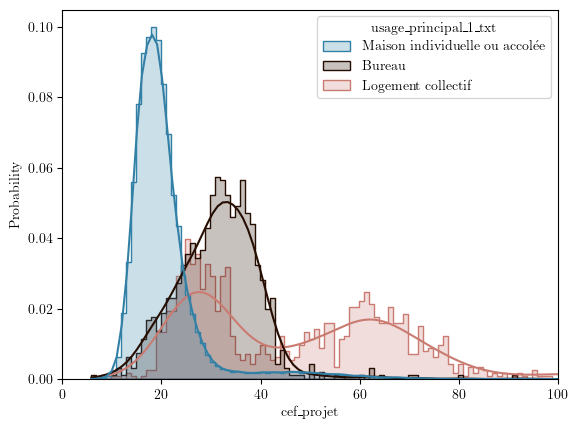

In [16]:
title = "distribution_cef_projet"

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "mathtext.fontset": "cm",
})


cmap = cm.berlin
n_hues = len(usages)

palette = list(cmap(np.linspace(0.2,0.9,n_hues)))

from datetime import datetime
today = datetime.today()


# plt.style.use("nord-light")
x="cef_projet"
fig,ax = plt.subplots()
g=sns.histplot(
        data =outliers(to_graph,x).filter(
            # pl.col("extreme_outliers")==False,
            ),
        x = x,
        stat="probability",
        hue="usage_principal_1_txt",
        # hue_order = usages,
        common_norm=False,
        kde = True,
        element = "step",
        ax = ax,
        binwidth = 1,
        palette = palette
    )
handles, labels = ax.get_legend_handles_labels()
# ax.legend(handles=handles[1:], labels=labels[1:])
sns.move_legend(ax, "upper left", bbox_to_anchor=(0.5, 1))
ax.set_xlim(0,100)

# plt.savefig(
#     f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",
#     dpi=300,
#     bbox_inches = "tight"
#     )

In [25]:
labels

[]

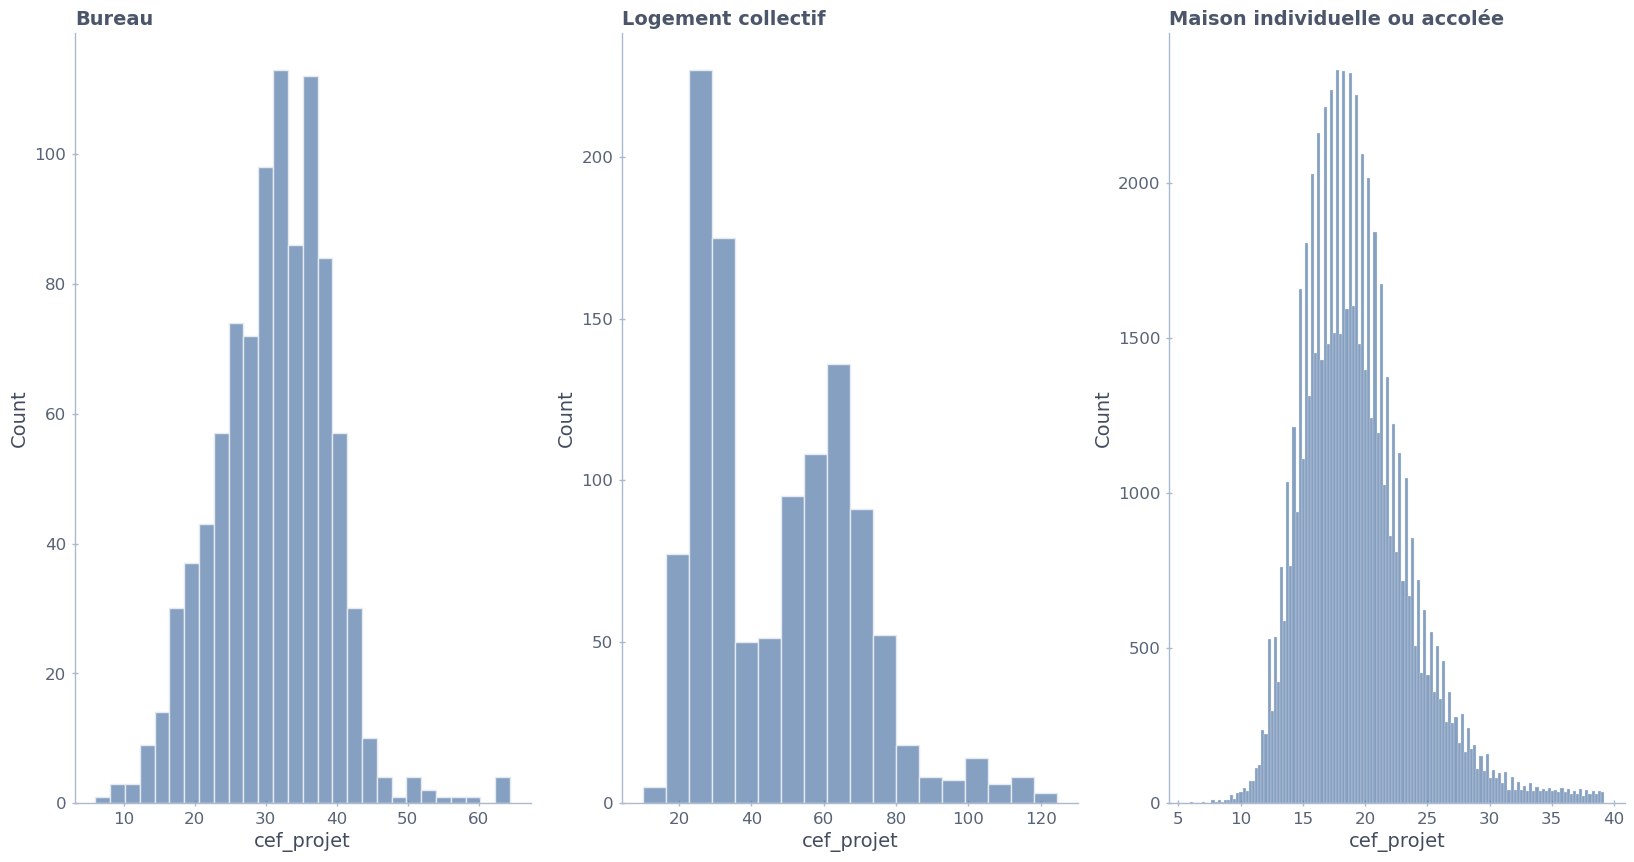

In [9]:
to_plot = [e for e in usages if "enseignement" not in str(e).lower()]
fig,ax = plt.subplots(1,len(to_plot),figsize = (20,10))

x = "cef_projet"
i=0

for u in  to_plot :
    tmp = to_graph.filter(pl.col("usage_principal_1_txt") == u)
    sns.histplot(
        data =outliers(tmp,x).filter(
            pl.col("extreme_outliers")==False,
            
            ),
        x = x,
        stat="count",
        # hue="usage_principal_1_txt",
        ax = ax[i]
    )
    ax[i].set_title(u)
    i+=1

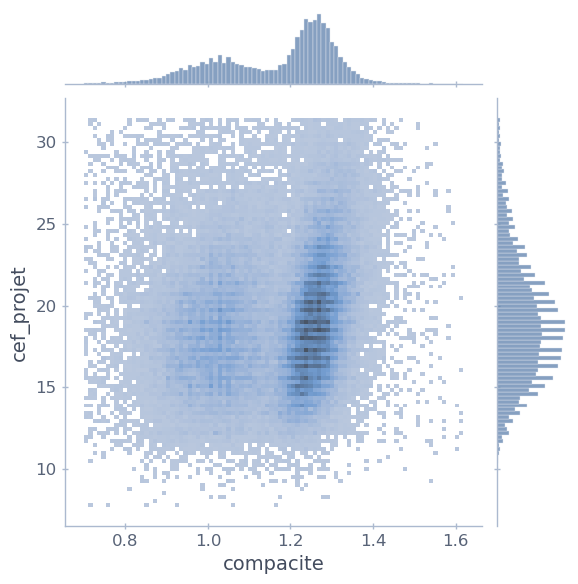

In [13]:
title = "cef_projet_vs_compacite"
from datetime import datetime
today = datetime.today()

x = "compacite"
y = "cef_projet"
sns.jointplot(
    data = mutli_outliers(
        to_graph,
        [x,y]
        ).filter(
                *[
                    (pl.col(f"extreme_outliers_{c}") == False) & (pl.col(f"mild_outliers_{c}") == False)
                    for c in [x,y]
                    ]
                ),
    x = x,
    y = y,
    # hue = "usage_principal_1_txt",
    kind = "hist",
    )

plt.savefig(
    f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",
    dpi=300,
    bbox_inches = "tight"
    )

In [5]:
to_graph

cef_projet,sref,volume,usage_principal_1_txt,emprise_au_sol,nb_niv_surface,compacite,facteur_taille,facteur_forme,sref_sur_emprise
f64,f64,f64,str,f64,i64,f64,f64,f64,f64
17.5,93.8,235.0,"""Maison individuelle ou accolée""",150.0,0,0.399149,6.171006,2.46315,0.625333
32.7,119.2,298.1,"""Bureau""",139.0,0,0.399866,6.680167,2.67117,0.857554
17.9,92.5,247.4,"""Maison individuelle ou accolée""",62.0,0,0.373888,6.27769,2.347156,1.491935
15.2,118.8,297.0,"""Maison individuelle ou accolée""",183.0,0,0.4,6.67194,2.668776,0.64918
14.6,170.3,461.3,"""Maison individuelle ou accolée""",245.0,0,0.369174,7.726708,2.8525,0.695102
…,…,…,…,…,…,…,…,…,…
38.5,121.0,302.5,"""Maison individuelle ou accolée""",120.0,0,0.4,6.712873,2.685149,1.008333
5.5,243.3,861.1,"""Enseignement primaire""",305.0,0,0.282546,9.513738,2.688065,0.797705
22.4,90.5,226.3,"""Maison individuelle ou accolée""",80.0,0,0.399912,6.093893,2.437019,1.13125


In [10]:
mutli_outliers(to_graph,["compacite","cef_projet"])

cef_projet,sref,volume,hauteur_hors_toiture,usage_principal_1_txt,emprise_au_sol,altitude,compacite,surface_baies_rset,surface_murs_rset,surface_plancher_bas_rset,surface_toiture_rset,sref_sur_V,facteur_taille,facteur_forme,sref_sur_emprise,mild_outliers_compacite,extreme_outliers_compacite,mild_outliers_cef_projet,extreme_outliers_cef_projet
f64,f64,f64,f64,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,bool,bool
17.5,93.8,235.0,2.5,"""Maison individuelle ou accolée""",150.0,"""0 à 400m""",1.32,20.9,97.1,96.1,96.1,0.399149,6.171006,2.46315,0.625333,false,false,false,false
32.7,119.2,298.1,2.5,"""Bureau""",139.0,"""0 à 400m""",1.266,19.8,119.3,119.2,119.2,0.399866,6.680167,2.67117,0.857554,false,false,true,false
17.9,92.5,247.4,5.39,"""Maison individuelle ou accolée""",62.0,"""0 à 400m""",1.019,19.3,131.8,50.5,50.5,0.373888,6.27769,2.347156,1.491935,false,false,false,false
15.2,118.8,297.0,2.5,"""Maison individuelle ou accolée""",183.0,"""0 à 400m""",1.286,25.2,119.2,118.8,118.8,0.4,6.67194,2.668776,0.64918,false,false,false,false
14.6,170.3,461.3,2.8,"""Maison individuelle ou accolée""",245.0,"""0 à 400m""",1.099,39.1,127.4,170.2,170.2,0.369174,7.726708,2.8525,0.695102,false,false,false,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
40.7,103.0,252.2,2.75,"""Maison individuelle ou accolée""",160.0,"""0 à 400m""",1.268,19.4,94.4,103.0,103.0,0.408406,6.31803,2.580322,0.64375,false,false,false,true
38.5,121.0,302.5,2.51,"""Maison individuelle ou accolée""",120.0,"""0 à 400m""",0.739,26.6,46.1,75.5,75.5,0.4,6.712873,2.685149,1.008333,false,false,true,false
22.4,90.5,226.3,5.63,"""Maison individuelle ou accolée""",80.0,"""0 à 400m""",1.067,19.5,123.0,49.4,49.6,0.399912,6.093893,2.437019,1.13125,false,false,false,false


In [11]:
plt.style.use("nord-light")

# usage = "Maison individuelle ou accolée"
# usage = "Logement collectif"
usage = "Bureau"
x,y = "sref_sur_emprise","nb_niv_surface"
# fig, ax = plt.subplots(1,3,figsize = (15,5))

sns.jointplot(
    data = mutli_outliers(
        to_graph.filter(
            pl.col("usage_principal_1_txt") == usage
            ),
            [x,y]
            ).filter(pl.col("nb_niv_surface")!=0,
                *[
                    (pl.col(f"extreme_outliers_{c}") == False) & (pl.col(f"mild_outliers_{c}") == False)
                    for c in [x,y]
                    ]
                ),
    x = x,
    y = y,
    # hue = "usage_principal_1_txt",
    kind = "reg",

    )

ColumnNotFoundError: "nb_niv_surface" not found

In [12]:
to_graph.drop_nulls().select("cef_projet", "facteur_forme","facteur_taille").corr()

cef_projet,facteur_forme,facteur_taille
f64,f64,f64
1.0,0.022471,0.110952
0.022471,1.0,0.111559
0.110952,0.111559,1.0


In [9]:
def comp_pave(h,long,larg) :
    return 2*(1/h+1/larg+1/long)


In [12]:
import numpy as np
h = 2.5
x = np.linspace(2,20,200)
y = np.linspace(2,20,200)
X,Y = np.meshgrid(x,y)
Z =  comp_pave(5, X, Y)


/tmp/ipykernel_50696/109073468.py:9: UserWarning: The following kwargs were not used by contour: 'color'
  ax.contour(X,Y,Z,levels=[1,1.25],color = "darkblue")


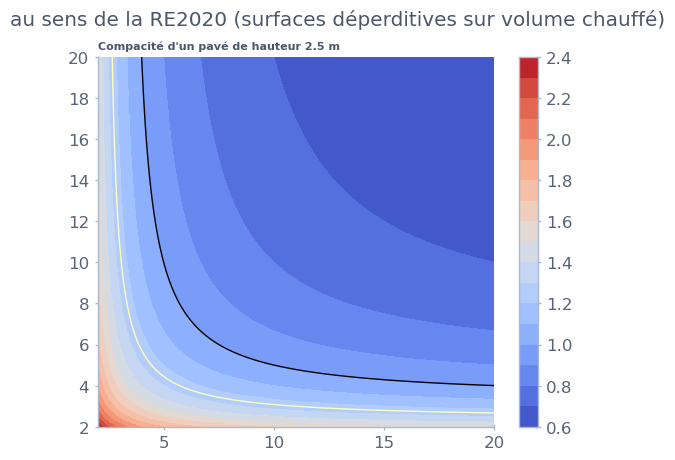

In [24]:
# plt.style.use("nord-light")
levels = np.linspace(Z.min(), Z.max(), 19)

# plot
fig, ax = plt.subplots()

g = ax.contourf(X, Y, Z, levels=levels,cmap = "coolwarm")

ax.contour(X,Y,Z,levels=[1,1.25],color = "darkblue")
ax.set_title(f"Compacité d'un pavé de hauteur {h} m",size = 8)
fig.suptitle("au sens de la RE2020 (surfaces déperditives sur volume chauffé)" )

fig.colorbar(g,ax=ax,)
plt.show()


# Tentative Clustering

In [150]:
# to_cluster = df_buildings.filter(pl.col("usage_principal_1_txt") == "Maison individuelle ou accolée").select("cef_projet","sref","volume","emprise_au_sol","compacite","surface_baies_rset","surface_murs_rset","surface_plancher_bas_rset","surface_toiture_rset")
to_cluster = df_buildings.filter(pl.col("usage_principal_1_txt") == "Maison individuelle ou accolée").select("cef_projet","compacite")


In [151]:
list_col = ["cef_projet","compacite"]
to_cluster = mutli_outliers(
    to_cluster, list_col
    ).filter(*[
        (pl.col(f"extreme_outliers_{c}") == False) & (pl.col(f"mild_outliers_{c}") == False)
                    for c in list_col
                    ])

In [152]:
from sklearn.cluster import MeanShift, k_means, MiniBatchKMeans,SpectralClustering, HDBSCAN
from sklearn.mixture import GaussianMixture

In [153]:
X = to_cluster.select(list_col).drop_nans().drop_nulls().to_numpy()

In [154]:
X

array([[17.5  ,  1.32 ],
       [17.9  ,  1.019],
       [15.2  ,  1.286],
       ...,
       [22.4  ,  1.067],
       [16.1  ,  1.156],
       [16.2  ,  1.086]])

In [156]:
labels = HDBSCAN(min_cluster_size=500).fit_predict(X)

/home/thibault.chevilliet@enpc.fr/miniconda3/envs/bw25_clean/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [157]:
to_cluster = to_cluster.with_columns(pl.Series("cluster_labels", labels))

In [158]:
to_cluster

cef_projet,compacite,mild_outliers_cef_projet,extreme_outliers_cef_projet,mild_outliers_compacite,extreme_outliers_compacite,cluster_labels
f64,f64,bool,bool,bool,bool,i64
17.5,1.32,false,false,false,false,-1
17.9,1.019,false,false,false,false,-1
15.2,1.286,false,false,false,false,-1
14.6,1.099,false,false,false,false,-1
21.3,1.321,false,false,false,false,-1
…,…,…,…,…,…,…
23.3,1.256,false,false,false,false,-1
20.3,1.039,false,false,false,false,-1
22.4,1.067,false,false,false,false,-1


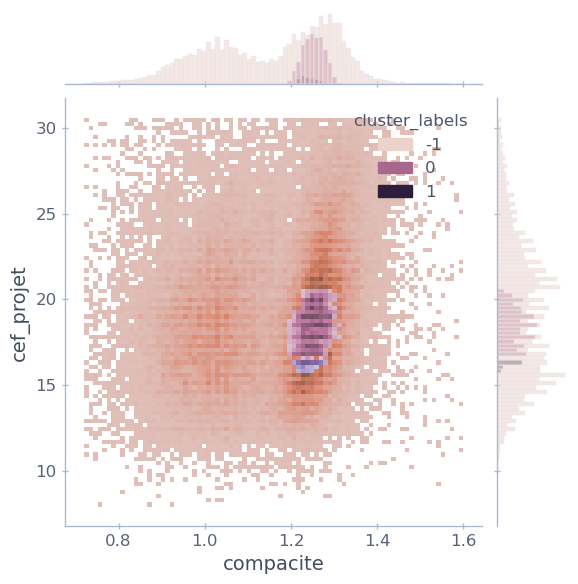

In [159]:
plt.style.use("nord-light")

x,y = "compacite","cef_projet"
# fig, ax = plt.subplots(1,3,figsize = (15,5))

sns.jointplot(
    data = to_cluster,
    x = x,
    y = y,
    hue = "cluster_labels",
    kind = "hist",

    )

In [12]:
from archetypes_re2020.utils.utils import *
import archetypes_re2020.utils.bw25_utils as bw25u
from archetypes_re2020.data.source import load_parquet_data
from archetypes_re2020.config import INTERIM_DATA_DIR
from archetypes_re2020.buildings.buildings_db import *
from archetypes_re2020.config import RAW_DATA_DIR, INTERIM_DATA_DIR

In [13]:
# Constantes
INPUT_PATH = INTERIM_DATA_DIR / "quantites_augmentees.parquet"
df_quant = load_parquet_data(INPUT_PATH)

In [14]:
df_quant.filter(pl.col("nomenclature_inies_1")=="Services")

projet_id,batiment_index,zone_index,lot_ref,sous_lot_ref,type_donnees,type_declaration,unite_uf_txt,nomenclature_inies_1,nomenclature_inies_2,nomenclature_inies_3,nomenclature_inies_4,nomenclature_inies_5,dve,quantite,nomenclatures,usage_principal_1_txt,sref,puissance_thermique_max_restituable_ch_1,puissance_thermique_max_restituable_ch_2,quant_surf,nomenclatures_UF,nomenclatures_UF_dve
i64,i64,i64,i64,f64,str,str,str,str,str,str,str,str,i64,f64,struct[5],str,f64,f64,f64,f64,struct[6],struct[7]
452132,1,1,8,1.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,50,3.8,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Maison individuelle ou accolée""",232.8,19.18,2.0,0.016323,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",50.0}"
452142,1,1,8,7.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,10,0.78,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Maison individuelle ou accolée""",109.3,16.83,7.0,0.007136,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",10.0}"
452152,1,1,8,7.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,50,9.0,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Logement collectif""",894.9,90.0,44.73,0.010057,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",50.0}"
452227,1,2,8,null,"""CONVENTIONNELLE""","""Individuelle""","""kWh""","""Services""","""Énergies""","""Combustibles""","""Bois""",null,50,1.0,"{""Services"",""Énergies"",""Combustibles"",""Bois"",null}","""Maison individuelle ou accolée""",102.0,24.14,null,0.009804,"{""Services"",""Énergies"",""Combustibles"",""Bois"",null,""kWh""}","{""Services"",""Énergies"",""Combustibles"",""Bois"",null,""kWh"",50.0}"
452227,1,2,10,null,"""CONVENTIONNELLE""","""Individuelle""","""kWh""","""Services""","""Énergies""","""Electricité""","""Résidentielle """,null,50,147.0,"{""Services"",""Énergies"",""Electricité"",""Résidentielle "",null}","""Maison individuelle ou accolée""",102.0,24.14,null,1.441176,"{""Services"",""Énergies"",""Electricité"",""Résidentielle "",null,""kWh""}","{""Services"",""Énergies"",""Electricité"",""Résidentielle "",null,""kWh"",50.0}"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
452081,1,1,8,1.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,50,1.2,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Maison individuelle ou accolée""",108.6,10.1,3.0,0.01105,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",50.0}"
452085,1,1,8,1.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,50,1.2,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Maison individuelle ou accolée""",130.7,10.56,null,0.009181,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",50.0}"
452086,1,1,8,1.0,"""CONVENTIONNELLE""",null,"""kg""","""Services""","""Fluides frigorigènes""",null,null,null,50,1.2,"{""Services"",""Fluides frigorigènes"",null,null,null}","""Maison individuelle ou accolée""",83.2,10.1,null,0.014423,"{""Services"",""Fluides frigorigènes"",null,null,null,""kg""}","{""Services"",""Fluides frigorigènes"",null,null,null,""kg"",50.0}"


In [15]:
df_buildings.select("presence_reseau","usage_principal_1_txt").values_count()

AttributeError: 'DataFrame' object has no attribute 'values_count'

In [16]:
df_buildings.columns

['altitude',
 'art_45',
 'batiment_conforme_re2020',
 'batiment_dc_id',
 'batiment_index',
 'batiment_rsenv_entree_projet_id',
 'batiment_rsenv_sortie_projet_id',
 'batiment_rset_entree_projet_id',
 'batiment_rset_sortie_projet_id',
 'q4pa_sparoi',
 'q4pa_sref',
 'brasseur_air_nb',
 'brasseur_air_rat_surf',
 'brasseur_air_qv_air_max',
 'bbio_ch_pts',
 'bbio_conforme',
 'bbio_ecl_pts',
 'bbio_fr_pts',
 'bbio_gain',
 'bbio_max',
 'bbio_projet',
 'capteur_pv_pc',
 'capteur_pv_surface',
 'categorie_ce',
 'cef_bois',
 'cef_bois_ch',
 'cef_bois_ecs',
 'cef_ch',
 'cef_depl',
 'cef_dist',
 'cef_ecl',
 'cef_ecs',
 'cef_elec',
 'cef_elec_ch',
 'cef_elec_depl',
 'cef_elec_dist',
 'cef_elec_ecl',
 'cef_elec_ecs',
 'cef_elec_fr',
 'cef_elec_mobi',
 'cef_elec_vent',
 'cef_fr',
 'cef_gaz',
 'cef_gaz_ch',
 'cef_gaz_ecs',
 'cef_gaz_fr',
 'cef_mobi',
 'cef_projet',
 'cef_reseau',
 'cef_reseau_ch',
 'cef_reseau_ecs',
 'cef_reseau_fr',
 'cef_vent',
 'cep_conforme',
 'cep_gain',
 'cep_max',
 'cep_nr_confor

In [17]:
to_graph = df_buildings.group_by('vecteur_energie_principal_ch', "usage_principal_1_txt").len()

In [22]:
to_graph

vecteur_energie_principal_ch,usage_principal_1_txt,len
str,str,u32
"""Génération fictive""","""Maison individuelle ou accolée""",67
"""Bois granulés + Électricité""","""Maison individuelle ou accolée""",1
"""Bois plaquettes""","""Logement collectif""",1
"""GPL""","""Logement collectif""",1
"""Électricité""","""Logement collectif""",554
…,…,…
"""Gaz naturel""","""Enseignement secondaire (parti…",5
"""Électricité""","""Enseignement secondaire (parti…",25
"""Réseau urbain""","""Enseignement secondaire (parti…",13


In [24]:
to_graph.pivot(on="usage_principal_1_txt",index = "vecteur_energie_principal_ch",values = "len").write_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/parts_vecteurs_ch.xlsx")

In [19]:
to_graph = to_graph.with_columns(
    pl.struct(pl.col(vecteur_energie_principal_ch))
)

NameError: name 'vecteur_energie_principal_ch' is not defined

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Maison individuelle ou accolée'),
  Text(1, 0, 'Logement collectif'),
  Text(2, 0, 'Bureau'),
  Text(3, 0, 'Enseignement secondaire (partie jour)'),
  Text(4, 0, 'Enseignement primaire')])

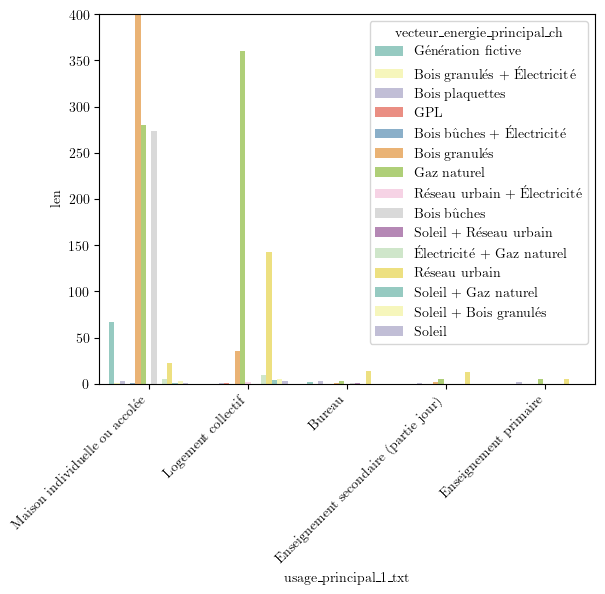

In [20]:
ax = sns.barplot(data=to_graph.filter(pl.col("vecteur_energie_principal_ch")!="Électricité"), x = "usage_principal_1_txt",y="len",hue = "vecteur_energie_principal_ch",palette="Set3")
ax.set_ylim(0,400)
plt.xticks(rotation=45, ha='right')

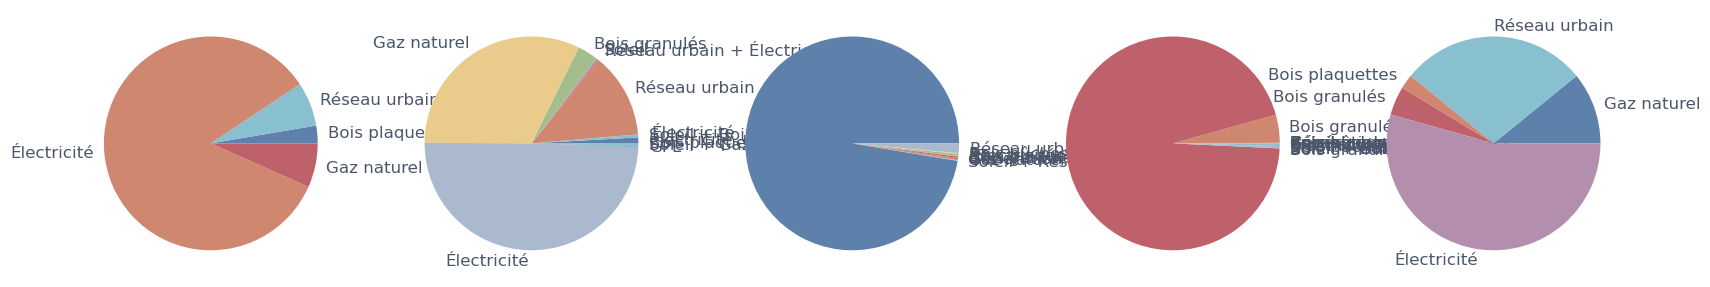

In [ ]:
import simplstyles
plt.style.use('nord-light')
usages = to_graph['usage_principal_1_txt'].unique().drop_nulls().to_list()

fig,axs=plt.subplots(1,len(usages),figsize = (20,5))

for usage,ax in zip(usages,axs) :
    tmp  = to_graph.filter(pl.col("usage_principal_1_txt")==usage).drop_nulls()

    ax.pie(tmp["len"].to_list(),labels = tmp["vecteur_energie_principal_ch"].to_list())

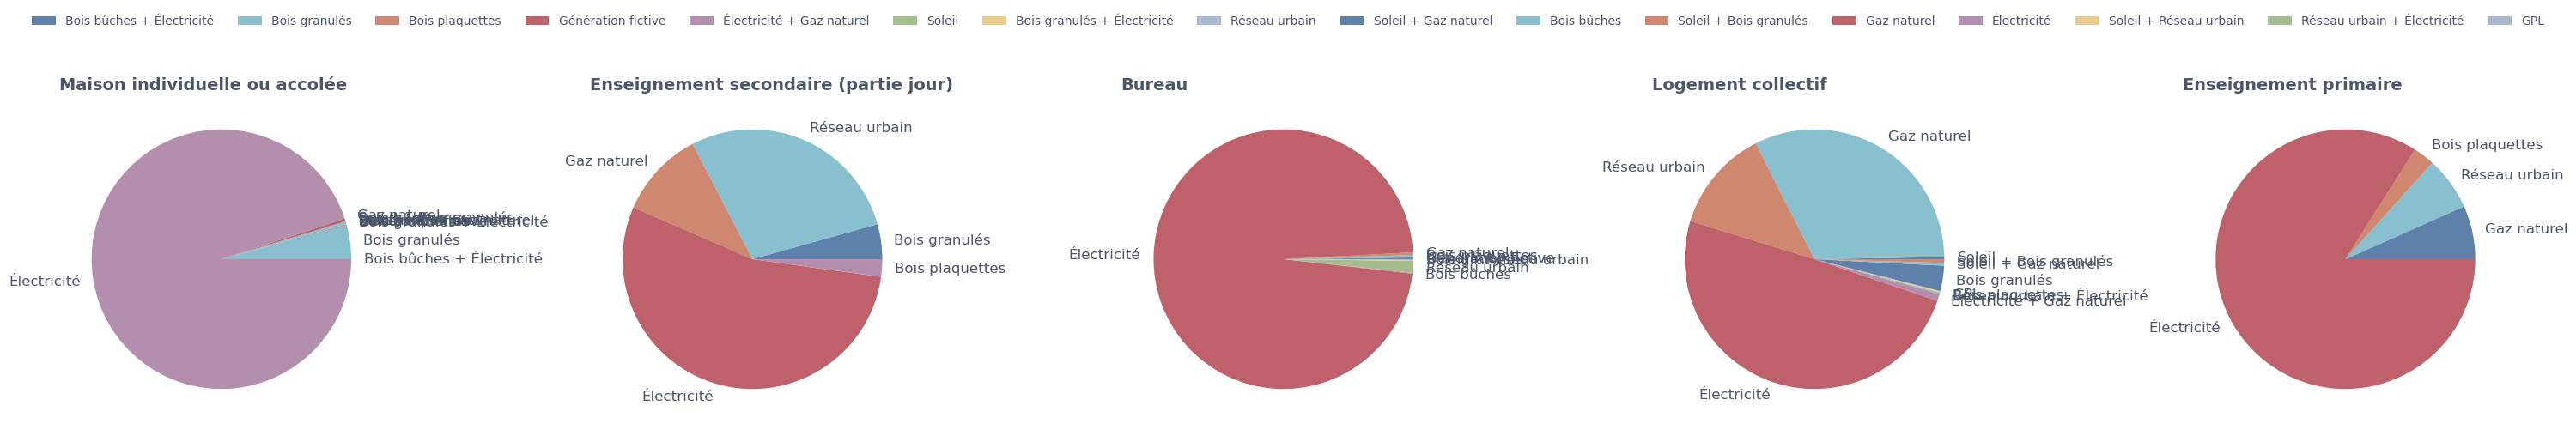

In [ ]:
import simplstyles
plt.style.use('nord-light')
usages = to_graph['usage_principal_1_txt'].unique().drop_nulls().to_list()

fig, axs = plt.subplots(1, len(usages), figsize=(30, 5))

all_wedges = []
all_labels = []

for usage, ax in zip(usages, axs):
    tmp = to_graph.filter(pl.col("usage_principal_1_txt") == usage).drop_nulls()
    
    
    wedges, texts = ax.pie(tmp["len"].to_list(), labels=tmp["vecteur_energie_principal_ch"].to_list())
    
    ax.set_title(usage)
    all_wedges.extend(wedges)
    all_labels.extend(tmp["vecteur_energie_principal_ch"].to_list())

# Get unique labels while preserving order and colors
seen = set()
unique_wedges = []
unique_labels = []
for wedge, label in zip(all_wedges, all_labels):
    if label not in seen:
        seen.add(label)
        unique_wedges.append(wedge)
        unique_labels.append(label)

# Add common legend outside the figure
fig.legend(unique_wedges, unique_labels, 
           loc='upper center', bbox_to_anchor=(0.5, 1.05), 
           ncol=len(unique_labels), fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to make room for legend
plt.show()

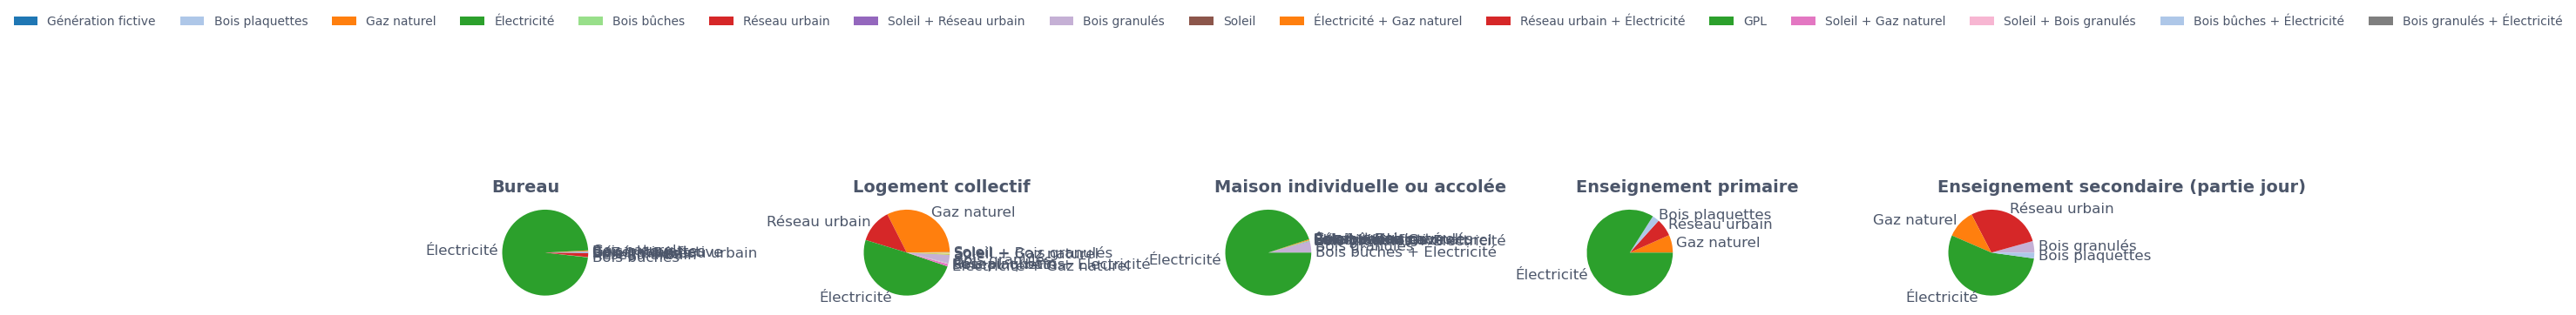

In [ ]:
import matplotlib.pyplot as plt
# import pandas as pd
import simplstyles
plt.style.use('nord-light')

usages = to_graph['usage_principal_1_txt'].unique().drop_nulls().to_list()

# First pass: collect all unique labels and assign consistent colors
all_labels = []
for usage in usages:
    tmp = to_graph.filter(pl.col("usage_principal_1_txt") == usage).drop_nulls()
    all_labels.extend(tmp["vecteur_energie_principal_ch"].to_list())

# Get unique labels in order of appearance
seen = set()
unique_labels = []
for label in all_labels:
    if label not in seen:
        seen.add(label)
        unique_labels.append(label)

# Create consistent color map
colors = plt.cm.(np.linspace(0, 1, len(unique_labels)))
label_to_color = dict(zip(unique_labels, colors))

# Second pass: create pie charts with consistent colors
fig, axs = plt.subplots(1, len(usages), figsize=(20, 5))

for usage, ax in zip(usages, axs):
    tmp = to_graph.filter(pl.col("usage_principal_1_txt") == usage).drop_nulls()
    
    labels = tmp["vecteur_energie_principal_ch"].to_list()
    sizes = tmp["len"].to_list()
    
    # Map each label to its consistent color
    chart_colors = [label_to_color[label] for label in labels]
    
    ax.pie(sizes, labels=labels, colors=chart_colors)
    ax.set_title(usage)

# Add common legend
fig.legend(unique_labels, 
           loc='upper center', 
           bbox_to_anchor=(0.5, 1.05), 
           ncol=len(unique_labels), 
           fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [29]:
color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [41]:
table = to_graph.drop_nulls("usage_principal_1_txt").pivot(on="usage_principal_1_txt",index="vecteur_energie_principal_ch").fill_null(0).sort("Maison individuelle ou accolée",descending=True)

In [46]:
for c in [col for col in table.columns if col != "vecteur_energie_principal_ch" ] :
    s = sum(table[c].to_list())
    table = table.with_columns(
        pl.col(c).map_elements(
            lambda x : x/s
        ).alias(f"{c}_relativ")
        )

/tmp/ipykernel_30809/1013352820.py:4: PolarsInefficientMapWarning: 
Expr.map_elements is significantly slower than the native expressions API.
Only use if you absolutely CANNOT implement your logic otherwise.
Replace this expression...
  - pl.col("Maison individuelle ou accolée").map_elements(lambda x: ...)
with this one instead:
  + pl.col("Maison individuelle ou accolée") / s

  pl.col(c).map_elements(
/tmp/ipykernel_30809/1013352820.py:4: PolarsInefficientMapWarning: 
Expr.map_elements is significantly slower than the native expressions API.
Only use if you absolutely CANNOT implement your logic otherwise.
Replace this expression...
  - pl.col("Logement collectif").map_elements(lambda x: ...)
with this one instead:
  + pl.col("Logement collectif") / s

  pl.col(c).map_elements(
/tmp/ipykernel_30809/1013352820.py:4: PolarsInefficientMapWarning: 
Expr.map_elements is significantly slower than the native expressions API.
Only use if you absolutely CANNOT implement your logic otherwise.

In [50]:
from datetime import datetime
today = datetime.today()

table.write_excel(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/{today.year}-{today.month}-{today.day}_type_energie_par_usage")

In [ ]:
table.select([c for c in table.columns if ("relativ" in str(c))]).write_excel(
    f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/{today.year}-{today.month}-{today.day}_type_energie_par_usage_relativ",
    conditional_forma)